# Utilize your Tools - Tutorials (2/2)
## Import the dataset
https://osf.io/jmz2n/overview --> "data_affect.csv"

https://github.com/kekistermann/Exploring-the-PsychometricToolbox

In [2]:
import pandas as pd
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

df = pd.read_csv("data_affect.csv")

#df_group1 = df[df["group"] == 1] # create a dataset containing only group 1 (control)
#df_group2 = df[df["group"] == 2] # create a dataset containing only group 2 (mindfulness training)

#df.head(241) # which displays all entries of the first person
df.head(7)

,subjno,dayno,beep,group,emo1_m,emo2_m,emo3_m,emo4_m,emo5_m,emo6_m,emo7_m,emo8_m
0,1,1,1,2,79.0,64.0,30.0,74.0,19.0,7.0,8.0,58.0
1,1,1,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,1,3,2,20.0,24.0,37.0,36.0,62.0,41.0,73.0,67.0
3,1,1,4,2,25.0,24.0,33.0,29.0,42.0,68.0,77.0,81.0
4,1,1,5,2,37.0,24.0,40.0,17.0,35.0,36.0,12.0,76.0
5,1,1,6,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,1,2,1,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# dataset consists of 125 persons
#print(df['subjno'].unique())

# Shows each unique subject → their group
#df[['subjno', 'group']].drop_duplicates().sort_values('subjno')

## Recurrence Plot (RP) & Recurrence Quantification Analysis (RQA) 

with 'pyunicorn' https://www.pik-potsdam.de/~donges/pyunicorn

In [12]:
import pyunicorn.timeseries

# print all the functions in the 'timeseries' class; https://www.pik-potsdam.de/~donges/pyunicorn/api_doc.html#timeseries
#dir(pyunicorn.timeseries) 

### Example: df["subjno"] == 120 (Figure 10)

In [3]:
# count the average number of observations (excluding NaNs) for a specific person per day
counts = df[df['subjno'] == 120].dropna()['dayno'].value_counts().sort_index()
average = counts.mean()
print(average)

5.5


Calculating recurrence plot at fixed threshold...
Calculating the euclidean distance matrix...


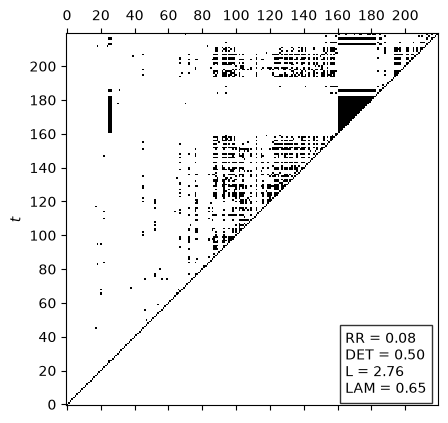

In [4]:
from pyunicorn.timeseries import RecurrencePlot
import numpy as np
import matplotlib.pyplot as plt

# select the person
person = 120

df_person = df[df["subjno"] == person] # filter the df for a specific person

df_person = df_person.iloc[:, -8:] # only keep the variable columns

# rename the columns
df_person.columns = (
    "happy",
    "excited",
    "relaxed",
    "satisfied",
    "angry",
    "anxious",
    "depressed",
    "sad",
)
# remove rows with NaN values
## --> which is ok to do because "the concept of recurrence plots does not require observations that are equally spaced in time."?
## see (10.1088/1367-2630/12/3/033025)
df_person = df_person.dropna() 


# https://www.pik-potsdam.de/~donges/pyunicorn/api/timeseries/recurrence_plot.html
## metric = "manhattan", "euclidean", or "supremum"
## .to_numpy() because we imported a pandas df, but we need a numpy array
RecPlo = RecurrencePlot(df_person.to_numpy(), metric="euclidean", normalize=True, threshold=0.7) 

# some summary statistics of the Recurrence Plot
stats = RecPlo.rqa_summary() 



plt.matshow(np.tril(RecPlo.recurrence_matrix()) , origin='lower', cmap="binary")
plt.ylabel("$t$")
plt.xticks(np.arange(0, len(df_person), 20))
plt.yticks(np.arange(0, len(df_person), 20))

txt = "\n".join(f"{k} = {v:.2f}" for k, v in stats.items())
plt.text(0.75, 0.2, txt, transform=plt.gca().transAxes,
    va="top",
    bbox=dict(facecolor="white", alpha=0.8)
)

plt.show()

**Noticable is the non-homogeneity, which strongly indicates non-stationarity of the time-series. The many isolated single points also point to some underlying stochasticity in the process. The presence of some diagonal line structures suggests that segments of the trajectory evolve in a similar manner at times, reflected in the moderate deterministic behavior (DET = 0.50). However, the relatively small average diagonal length (L = 2.76) indicates that this predictability is short-lived, especially when considering that usually there are six observations per day. The noticeable vertical and horizontal line structures and the relatively high Laminarity value (LAM = 0.65) point to phases during which the system remains temporarily in similar states. An interesting question to investigate might be whether the control and intervention groups differ in their RQA metrics. But the theoretical interpretation of these metrics in the psychometric context remains an open question for now.**


So there definitly seems to be some structure in the data for this particular person, but a intelligible interpretation of how this translates back in the dynamics of the 8 emotion variables is hard. But some observations can be noted:
- for the big black square (around 160-180) and small balck stripe (around 25): all 4 positive emotion variables close to 100, and all 4 negative emotion variables close to 0
- for the bigger square with gaps befor that (around 80-160): positive emotion variables fluctuating around 85, and negative emotion variables close to 0

**Note: Recurrence in different regions of the state space are not differentiated in the Recurrence Plots, but this would proably be interesting to know.**

In [11]:
# check a specific part of a dataset

df_person.iloc[150:170]

,happy,excited,relaxed,satisfied,angry,anxious,depressed,sad
22245,76.0,83.0,76.0,74.0,1.0,3.0,0.0,10.0
22246,81.0,81.0,75.0,76.0,0.0,2.0,3.0,1.0
22247,83.0,85.0,82.0,80.0,0.0,1.0,0.0,0.0
22248,95.0,89.0,84.0,93.0,1.0,2.0,6.0,1.0
22249,84.0,84.0,77.0,82.0,0.0,0.0,1.0,0.0
22250,81.0,84.0,84.0,80.0,1.0,4.0,4.0,0.0
22252,84.0,88.0,82.0,81.0,1.0,0.0,1.0,2.0
22253,84.0,88.0,90.0,84.0,0.0,0.0,3.0,1.0
22254,87.0,84.0,85.0,80.0,2.0,0.0,0.0,2.0
22256,84.0,88.0,87.0,95.0,0.0,1.0,0.0,0.0


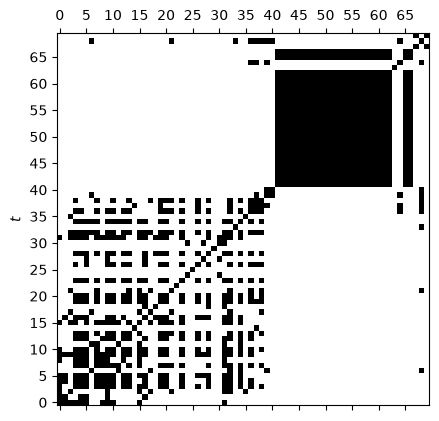

In [15]:
# "zoom in" on a range of time points (t)
start = 120
end = 190

plt.matshow(RecPlo.recurrence_matrix()[start:end, start:end], origin='lower', cmap="binary")
plt.ylabel("$t$")
plt.xticks(np.arange(0, end-start, 5))
plt.yticks(np.arange(0, end-start, 5))
plt.show()

#### generate and save a RP for each person in the dataset

In [18]:
import pandas as pd
import os

individuals = df['subjno'].unique()

# define where images will be saved
out_dir = os.path.join(os.getcwd(), "RecurrencePlots")
os.makedirs(out_dir, exist_ok=True)


for i in individuals:
    df_person = df[df["subjno"] == i] # filter the df for a specific person
    df_person = df_person.iloc[:, -8:] # only keep the variable columns
    df_person = df_person.dropna() # remove rows with NaN values --> which is ok to do because "the concept of recurrence plots does not require observations that are equally spaced in time."?

    # metric = "manhattan", "euclidean", or "supremum"
    RecPlo = RecurrencePlot(df_person.to_numpy(), metric="euclidean", normalize=True, threshold=0.7) # .to_numpy() because we imported a pandas df, but we need a numpy array
    
    stats = RecPlo.rqa_summary()

    plt.matshow(np.tril(RecPlo.recurrence_matrix()), origin='lower', cmap="binary")
    plt.xlabel("$t$"); plt.ylabel("$t$")
    plt.xticks(np.arange(0, len(df_person), 20))
    plt.yticks(np.arange(0, len(df_person), 20))

    txt = "\n".join(f"{k} = {v:.2f}" for k, v in stats.items())
    plt.text(
        0.75, 0.2, txt, transform=plt.gca().transAxes,
        va="top",
        bbox=dict(facecolor="white", alpha=0.8)
        )
    
    # build filename (one file per subject)
    filename = f"figure_RecurrencePlot_person_{i}.jpg"
    filepath = os.path.join(out_dir, filename)

    plt.savefig(filepath, dpi=300, bbox_inches="tight")
    plt.close()   # important to avoid memory buildup
    


Calculating recurrence plot at fixed threshold...
Calculating the euclidean distance matrix...
Calculating recurrence plot at fixed threshold...
Calculating the euclidean distance matrix...
Calculating recurrence plot at fixed threshold...
Calculating the euclidean distance matrix...
Calculating recurrence plot at fixed threshold...
Calculating the euclidean distance matrix...
Calculating recurrence plot at fixed threshold...
Calculating the euclidean distance matrix...
Calculating recurrence plot at fixed threshold...
Calculating the euclidean distance matrix...
Calculating recurrence plot at fixed threshold...
Calculating the euclidean distance matrix...
Calculating recurrence plot at fixed threshold...
Calculating the euclidean distance matrix...
Calculating recurrence plot at fixed threshold...
Calculating the euclidean distance matrix...
Calculating recurrence plot at fixed threshold...
Calculating the euclidean distance matrix...
Calculating recurrence plot at fixed threshold...
